# K-means Clustering 

### Project Overview
In this project, we'll build a k-means clustering algorithm from scratch. Clustering is an unsupervised machine learning technique that can find patterns in your data. K-means is one of the most popular forms of clustering.

We'll create our algorithm using python and pandas. We'll then compare it to the reference implementation from scikit-learn.

### Project Steps

Write out pseudocode for the algorithm
Code the k-means algorithm
Plot the clusters from the algorithm
Compare performance to the scikit-learn algorithm
K-means overview
K-means is an unsupervised machine learning technique that allow us to cluster data points. This enables us to find patterns in the data that can help us analyze it more effectively. K-means is an iterative algorithm, which means that it will converge to the optimal clustering over time.

### To run a k-means clustering:

Specify the number of clusters you want (usually referred to as k).
Randomly initialize the centroid for each cluster. The centroid is the data point that is in the center of the cluster.
Determine which data points belong to which cluster by finding the closest centroid to each data point.
Update the centroids based on the geometric mean of all the data points in the cluster.
Run 3 and 4 until the centroids stop changing. Each run is referred to as an iteration.


### Code
You can find the code for this project here.

### File overview:

clustering.ipynb - the full code from this project
Local Setup
Installation
To follow this project, please install the following locally:

Python 3.8+
Python packages
pandas
numpy
scikit-learn

### Importation

In [41]:
import numpy as np
import pandas as pd 

In [42]:
df = pd.read_excel('Career Mode female player datasets - FIFA 16-22.xlsx')
df.head()

,sofifa_id,player_url,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,...,lcb,cb,rcb,rb,gk,player_face_url,club_logo_url,club_flag_url,nation_logo_url,nation_flag_url
0,226324,https://sofifa.com/player/226324/carli-lloyd/1...,C. Lloyd,Carli Anne Hollins,"CM, CAM, LM, ST",91,91,NaN,NaN,32,...,82+3,82+3,82+3,83+3,19+3,https://cdn.sofifa.com/players/226/324/16_120.png,NaN,NaN,https://cdn.sofifa.com/teams/113009/60.png,https://cdn.sofifa.com/flags/us.png
1,226328,https://sofifa.com/player/226328/megan-rapinoe...,M. Rapinoe,Megan Anna Rapinoe,"LM, CM",90,90,NaN,NaN,29,...,56+3,56+3,56+3,66+3,19+3,https://cdn.sofifa.com/players/226/328/16_120.png,NaN,NaN,https://cdn.sofifa.com/teams/113009/60.png,https://cdn.sofifa.com/flags/us.png
2,226334,https://sofifa.com/player/226334/abby-wambach/...,A. Wambach,Abby Wambach,ST,90,90,NaN,NaN,35,...,55+3,55+3,55+3,55+3,20+3,https://cdn.sofifa.com/players/226/334/16_120.png,NaN,NaN,https://cdn.sofifa.com/teams/113009/60.png,https://cdn.sofifa.com/flags/us.png
3,226362,https://sofifa.com/player/226362/louisa-necib/...,L. Nécib,Louisa Nécib,"LM, CAM",90,90,NaN,NaN,28,...,61+3,61+3,61+3,69+3,20+3,https://cdn.sofifa.com/players/226/362/16_120.png,NaN,NaN,https://cdn.sofifa.com/teams/113003/60.png,https://cdn.sofifa.com/flags/fr.png
4,226373,https://sofifa.com/player/226373/nadine-kessle...,N. Keßler,Nadine Keßler,CM,89,89,NaN,NaN,27,...,79+3,79+3,79+3,80+3,20+3,https://cdn.sofifa.com/players/226/373/16_120.png,NaN,NaN,https://cdn.sofifa.com/teams/113004/60.png,https://cdn.sofifa.com/flags/de.png


In [43]:
df.columns

Index(['sofifa_id', 'player_url', 'short_name', 'long_name',
       'player_positions', 'overall', 'potential', 'value_eur', 'wage_eur',
       'age',
       ...
       'lcb', 'cb', 'rcb', 'rb', 'gk', 'player_face_url', 'club_logo_url',
       'club_flag_url', 'nation_logo_url', 'nation_flag_url'],
      dtype='object', length=110)

In [44]:
df.shape # a lot of columns n lignes 

(248, 110)

In [45]:
 # select the columns(features) import
features = ['overall','potential','wage_eur','value_eur','age']

In [46]:
# Replace NaN with the mean of each column
df[features] = df[features].fillna(df[features].mean())

# Or, if you prefer median:
# df[features] = df[features].fillna(df[features].median())

# Or mode (most frequent value):
# df[features] = df[features].fillna(df[features].mode().iloc[0])

# Display the updated DataFrame
print(df[features].head())


   overall  potential  wage_eur  value_eur  age
0       91         91       NaN        NaN   32
1       90         90       NaN        NaN   29
2       90         90       NaN        NaN   35
3       90         90       NaN        NaN   28
4       89         89       NaN        NaN   27


In [47]:
df[features].isna().sum()

overall        0
potential      0
wage_eur     248
value_eur    248
age            0
dtype: int64

In [49]:
df=df[features].drop(['wage_eur','value_eur'],axis=1)
df.isna().sum()

overall      0
potential    0
age          0
dtype: int64

In [51]:
df.shape

(248, 3)

### steps 
* scale data (in same echelle or range)-(so no column dominate other)
* Iinialize random centroids
* Label each data point
* update centroids
* reapeat the 2 previous steps until centroids stop changing

### scaling data (Normalisation)

In [52]:
df = ((df -df.min())/ (df.max()-df.min()))*9 +1


<bound method NDFrame.describe of      overall  potential       age
0       10.0      10.00  6.571429
1        9.7       9.64  5.285714
2        9.7       9.64  7.857143
3        9.7       9.64  4.857143
4        9.4       9.28  4.428571
..       ...        ...       ...
243      2.2       2.08  3.571429
244      1.9       2.80  2.714286
245      1.9       3.16  2.285714
246      1.6       1.72  1.857143
247      1.0       1.00  3.142857

[248 rows x 3 columns]>

In [53]:
df.describe() #after scaling no columns will dominate other in clusttering

,overall,potential,age
count,248.000000,248.000000,248.000000
mean,5.445565,5.861452,4.091590
std,1.640819,1.921123,1.742183
min,1.000000,1.000000,1.000000
25%,4.300000,4.600000,2.714286
50%,5.200000,6.040000,4.000000
75%,6.400000,7.120000,5.285714
max,10.000000,10.000000,10.000000


In [61]:
df.head()

,overall,potential,age
0,10.0,10.00,6.571429
1,9.7,9.64,5.285714
2,9.7,9.64,7.857143
3,9.7,9.64,4.857143
4,9.4,9.28,4.428571


### Iinialize random centroids

In [89]:
def random_centroids(df, k):
    centroids = []
    for i in range(k):
        # sample one value from each column and convert to float
        centroid = df.apply(lambda x: float(x.sample().iloc[0]))
        centroids.append(centroid)  # append to the list
    return pd.concat(centroids, axis=1)


* Explanation:
  
* df.apply(lambda x: float(x.sample()))  
→ For each column x, it randomly samples one value and converts it to float.


→ This gives you a Series representing one centroid.

* centroids.append(centroid)  
→ You need to store each centroid in the list. Without this, your list stays empty.

* pd.concat(centroids, axis=1)  
→ Combines all centroid Series into a DataFrame, where each column is one centroid.

In [90]:
centroids = random_centroids(df,5)
centroids

,0,1,2,3,4
overall,6.700000,5.200000,3.400000,7.300000,4.60
potential,4.960000,6.400000,3.520000,5.320000,6.76
age,4.428571,5.285714,2.714286,5.714286,4.00


## Label each data point (find distance btw data and centroids)

In [91]:
def get_labels(data, centroids):
    # compute distances from each row in data to each centroid
    distances = pd.DataFrame({
        i: np.sqrt(((data - centroids.iloc[:, i])**2).sum(axis=1))
        for i in range(centroids.shape[1])
    })
    
    # assign each row to the closest centroid
    labels = distances.idxmin(axis=1)
    return labels


In [92]:
labels = get_labels(df,centroids)

In [93]:
labels.value_counts()

4    93
2    55
3    53
0    27
1    20
Name: count, dtype: int64

## update centroids
update centroids base on whose in the cluster(mean of cluster and adjust the centroid to it )

In [97]:

def new_centroids(data, labels, k):
    centroids = []
    for i in range(k):
        cluster_points = data[labels == i]
        if not cluster_points.empty:
            centroid = cluster_points.mean()
            centroids.append(centroid)
    return pd.concat(centroids, axis=1)   # make sure to return!

#split dataframe by labels 
# to each group we're applying this lambda function that calcute the geometrique mean for each feature
# which is the cluster centroids = give us new centroids

## reapeat the 2 previous steps until centroids stop changing(LOOP)

In [98]:
# visualise the loop
from sklearn.decomposition import PCA 
import matplotlib.pyplot as plt
from IPython.display import clear_output #help us to clear the jupyter output befor putting new graphe

In [99]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from IPython.display import clear_output

def plot_clusters(data, labels, centroids, iteration):
    # transform data into PCA 2D
    pca = PCA(n_components=2)
    data_2d = pca.fit_transform(data)          # use the function argument, not df
    centroids_2d = pca.transform(centroids.T)  # transpose so centroids are rows
    
    # Plot and visualise the clusters
    clear_output(wait=True)
    plt.figure(figsize=(8,6))
    plt.title(f'Iteration {iteration}')
    
    # plot data points colored by cluster labels
    plt.scatter(data_2d[:,0], data_2d[:,1], c=labels, cmap='viridis', alpha=0.6)
    
    # plot centroids as red X markers
    plt.scatter(centroids_2d[:,0], centroids_2d[:,1], marker='X', s=200, c='red')
    
    plt.show()


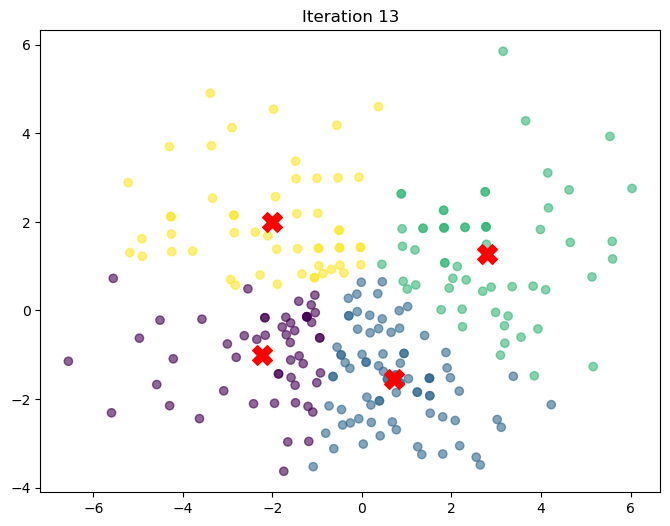

In [104]:
max_iterations = 100          # number of repetitions allowed
centroid_count = 4        # number of clusters

# initialise centroids randomly
centroids = random_centroids(df, centroid_count)

# initialise old centroids as empty
old_centroids = pd.DataFrame()

iteration = 1

# loop until max_iterations OR centroids stop changing
while iteration < max_iterations and not centroids.equals(old_centroids):
    old_centroids = centroids
    
    # assign each data point to the closest centroid
    labels = get_labels(df, centroids)
    
    # update centroids based on cluster assignments
    centroids = new_centroids(df, labels, centroid_count)
    
    # visualise clusters at this iteration
    plot_clusters(df, labels, centroids, iteration)
    
    iteration += 1


In [106]:
centroids

,0,1,2,3
overall,3.762264,5.362651,7.681356,4.769811
potential,4.321509,6.825060,7.681356,3.866415
age,3.191375,2.683305,5.184019,5.981132


In [110]:
#compare to implimentaion in sklearn
from sklearn.cluster import KMeans
import pandas as pd

# keep only the actual columns you have in your DataFrame
features = ['overall', 'potential', 'age']

# fit KMeans on those features
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(df[features])

# convert cluster centers into a DataFrame
centroids_df = pd.DataFrame(kmeans.cluster_centers_, columns=features).T

print(centroids_df)


                  0         1         2         3
overall    5.658571  4.026087  7.758491  4.739286
potential  7.197143  4.761739  7.663396  3.841429
age        2.683673  3.062112  5.374663  5.905612


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


#### the results are kinda diff  btw :
* ur own kmean clustering (best way to learn +gives more flixibity to change and adjust+look good in cv and interviews too)
  
* kmeans sklearn